In [ ]:
import torch

gpu_disponibile = torch.cuda.is_available()
nome_device = torch.cuda.get_device_name(0) if gpu_disponibile else "Nessuna GPU (CPU in uso)"

print(f"GPU Disponibile: {gpu_disponibile}")
print(f"Dispositivo in uso: {nome_device}")

In [11]:
num_samples = 1600  # Numero totale di campioni sintetici
seq_len = 64  # Numero di punti per onda sinusoidale
batch_size = 16

print(
    f"Parametri configurati: {num_samples} campioni, lunghezza sequenza"
    f" {seq_len}, batch size {batch_size}"
)

Parametri configurati: 1600 campioni, lunghezza sequenza 64, batch size 16


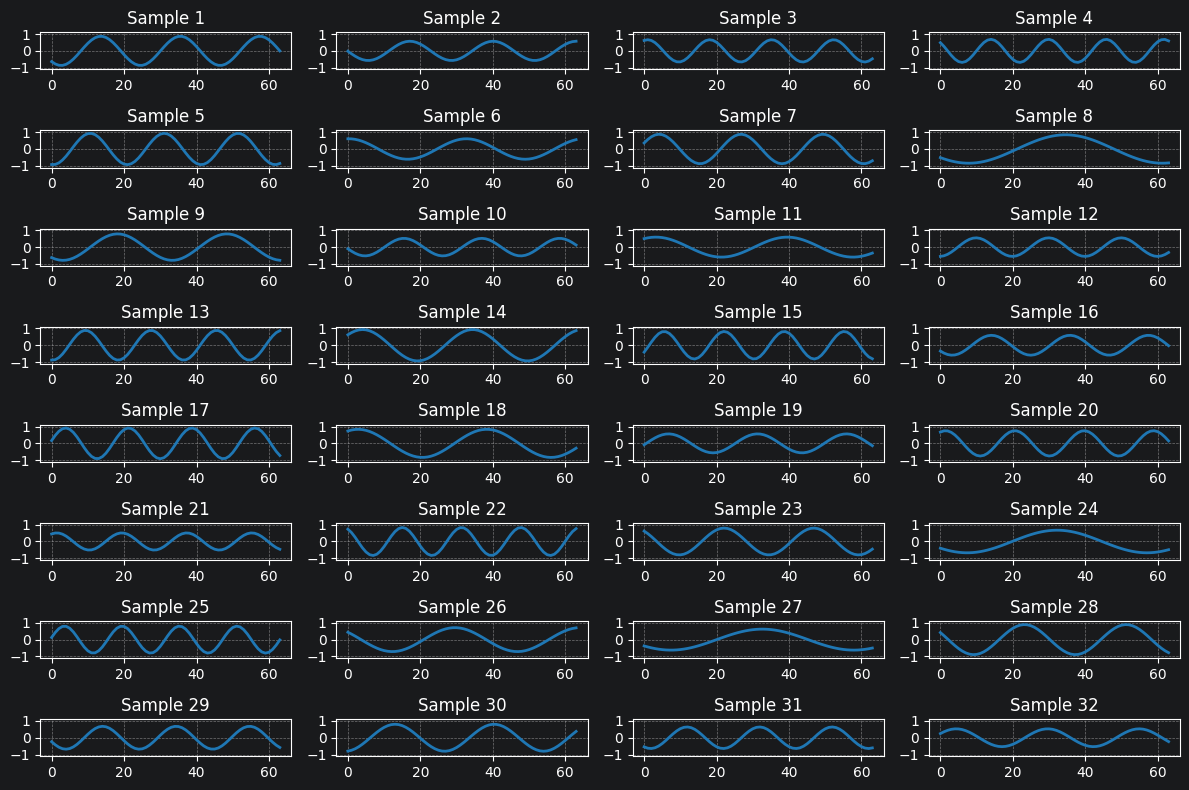

In [12]:
import matplotlib.pyplot as plt

# I valori sono generati per essere nativamente nell'intervallo [-1, 1]
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, random_split


class SineWaveDataset(Dataset):
    def __init__(self, num_samples=1600, seq_len=64, noise_std=0.0):
        super().__init__()
        self.num_samples = num_samples
        self.seq_len = seq_len

        np.random.seed(42)
        t = np.linspace(0, 4 * np.pi, seq_len)  # Aggiunto *

        data = []
        for _ in range(num_samples):
            freq = np.random.uniform(0.5, 2.0)
            phase = np.random.uniform(0, 2 * np.pi)  # Aggiunto *
            amplitude = np.random.uniform(0.5, 1.0)

            wave = amplitude * np.sin(freq * t + phase)
            if noise_std > 0:
                wave += np.random.normal(0, noise_std, seq_len)

            wave = np.clip(wave, -1.0, 1.0)
            data.append(wave)

        # Tensor con forma (num_samples, 1, seq_len) per compatibilità con Conv1D
        self.data = torch.tensor(np.array(data), dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], 0  # Etichetta fittizia


# Parametri
num_samples = 1600
seq_len = 64
batch_size = 32

dataset = SineWaveDataset(num_samples=num_samples, seq_len=seq_len)

# Split Training / Test
train_size = int(0.8 * len(dataset))  # Aggiunto *
test_size = len(dataset) - train_size  # Aggiunto -
train_dataset, test_dataset = random_split(
    dataset, [train_size, test_size], generator=torch.Generator().manual_seed(42)
)

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
dataloader = train_dataloader


# Visualizzazione
def show_batch(loader, cols=4):
    samples, _ = next(iter(loader))
    num_samples = len(samples)
    rows = (num_samples + cols - 1) // cols

    plt.figure(figsize=(12, 8))
    for i, sample in enumerate(samples):
        plt.subplot(rows, cols, i + 1)
        signal = sample.squeeze(0).numpy()
        plt.plot(signal, color='tab:blue', linewidth=2)
        plt.ylim(-1.1, 1.1)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.title(f'Sample {i + 1}')

    plt.tight_layout()
    plt.show()


show_batch(dataloader)

In [13]:
import torch
import torch.nn.functional as F

#  Definizione dello Schedule dei Beta
def linear_beta_schedule(timesteps, start=0.0001, end=0.02):
    return torch.linspace(start, end, timesteps)


# Pre-calcolo dei parametri globali (per T=300 timesteps)
T = 300
betas = linear_beta_schedule(timesteps=T)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

# Termini utili per il forward process e l'inferenza
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)


# Funzione helper per estrarre l'indice t mantenendo le dimensioni del batch
def get_index_from_list(vals, t, x_shape):
    """
    Estrae il valore corrispondente al timestep t da 'vals'
    e lo ridimensiona a (batch_size, 1, 1, ...) per il broadcasting.
    """
    batch_size = t.shape[0]
    out = vals.gather(-1, t.cpu())
    # Crea una forma del tipo [batch_size, 1, 1] in base al numero di dimensioni del dato
    shape = [batch_size] + [1] * (len(x_shape) - 1)
    return out.reshape(shape).to(t.device)


# Processo di diffusione in avanti (Forward Process)
def forward_diffusion_sample(x_0, t, device="cpu"):
    """
    Prende un campione pulito x_0 e un timestep t,
    e ne restituisce la versione rumorosa x_t insieme al rumore applicato.
    """
    x_0 = x_0.to(device)
    t = t.to(device)

    noise = torch.randn_like(x_0)

    sqrt_alphas_cumprod_t = get_index_from_list(sqrt_alphas_cumprod, t, x_0.shape)
    sqrt_one_minus_alphas_cumprod_t = get_index_from_list(
        sqrt_one_minus_alphas_cumprod, t, x_0.shape
    )

    # Formula x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise
    x_t = sqrt_alphas_cumprod_t * x_0 + sqrt_one_minus_alphas_cumprod_t * noise

    return x_t, noise

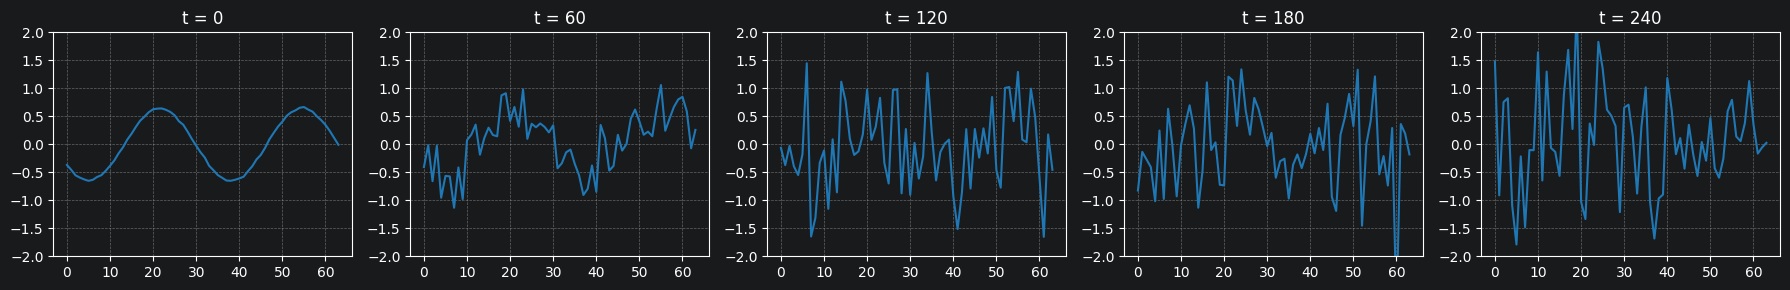

In [14]:
import matplotlib.pyplot as plt
import torch

# Prendi un campione pulito direttamente dal dataset
x_0, _ = train_dataset[0]  # Forma (1, 64)
x_0 = x_0.unsqueeze(0)  # Aggiungi batch dimension -> (1, 1, 64)

plt.figure(figsize=(18, 3))
num_images = 5
stepsize = int(T / num_images)

# Genera gli indici in base a T
for i, idx in enumerate(range(0, T, stepsize)):
    # Usiamo dtype=torch.long che è lo standard per gli indici
    t = torch.tensor([idx], dtype=torch.long)

    # Diffusione
    img_t, noise = forward_diffusion_sample(x_0, t)

    # Rimuoviamo automaticamente tutte le dimensioni da 1 (batch e canali)
    signal = img_t.squeeze().cpu().numpy()

    # Creiamo esattamente num_images colonne (nessun box vuoto)
    plt.subplot(1, num_images, i + 1)
    plt.plot(signal, color='tab:blue')
    plt.ylim(-2.0, 2.0)
    plt.title(f"t = {idx}")
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [15]:
import math
import torch
import torch.nn as nn


class SinusoidalPositionEmbeddings(nn.Module):
    """Genera l'embedding posizionale sinusoidale per il timestep t."""

    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, time: torch.Tensor) -> torch.Tensor:
        device = time.device
        half_dim = self.dim // 2

        emb = math.log(10000.0) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device, dtype=torch.float32) * -emb)
        emb = time[:, None].float() * emb[None, :]

        embeddings = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return embeddings


class ConvBlock1D(nn.Module):
    """Blocco convoluzionale base 1D con iniezione del timestep a metà."""

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        # Prima parte: estrae le feature
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True)
        )
        # Seconda parte: elabora feature + tempo
        self.conv2 = nn.Sequential(
            nn.Conv1d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x: torch.Tensor, t_emb: torch.Tensor = None) -> torch.Tensor:
        # Passaggio nella prima convoluzione
        h = self.conv1(x)

        # Iniezione del timestep (se fornito)
        if t_emb is not None:
            # t_emb ha forma (batch_size, out_ch)
            # Aggiungiamo la dimensione spaziale per il broadcasting -> (batch, out_ch, 1)
            h = h + t_emb.unsqueeze(-1)

        # Passaggio nella seconda convoluzione
        out = self.conv2(h)
        return out


class SimpleUnet1D(nn.Module):
    """U-Net 1D standard per DDPM con iniezione del tempo in ogni blocco."""

    def __init__(self, in_channels: int = 1, out_channels: int = 1, time_emb_dim: int = 32):
        super().__init__()

        # --- Time Embedding MLP ---
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.ReLU()
        )

        # Proiezioni del tempo (allineate ai canali di uscita del primo conv di ogni blocco)
        self.time_emb_enc1 = nn.Linear(time_emb_dim, 32)
        self.time_emb_enc2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_bottleneck = nn.Linear(time_emb_dim, 128)
        self.time_emb_dec2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_dec1 = nn.Linear(time_emb_dim, 32)

        # --- Encoder ---
        self.enc1 = ConvBlock1D(in_channels, 32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)  # 64 -> 32

        self.enc2 = ConvBlock1D(32, 64)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)  # 32 -> 16

        # --- Bottleneck ---
        self.bottleneck = ConvBlock1D(64, 128)

        # --- Decoder ---
        # input del dec2 è 128 (64 dal salto + 64 dalla up2). L'uscita di conv1 dentro dec2 sarà 64
        self.up2 = nn.ConvTranspose1d(128, 64, kernel_size=2, stride=2)
        self.dec2 = ConvBlock1D(128, 64)

        # input del dec1 è 64 (32 dal salto + 32 dalla up1). L'uscita di conv1 dentro dec1 sarà 32
        self.up1 = nn.ConvTranspose1d(64, 32, kernel_size=2, stride=2)
        self.dec1 = ConvBlock1D(64, 32)

        # --- Output ---
        self.out_conv = nn.Conv1d(32, out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # Calcola l'embedding base del timestep t
        t_emb = self.time_mlp(t)

        # Encoder
        e1 = self.enc1(x, self.time_emb_enc1(t_emb))
        p1 = self.pool1(e1)

        e2 = self.enc2(p1, self.time_emb_enc2(t_emb))
        p2 = self.pool2(e2)

        # Bottleneck
        b = self.bottleneck(p2, self.time_emb_bottleneck(t_emb))

        # Decoder con Skip Connections
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)  # Concatena skip connection
        d2 = self.dec2(d2, self.time_emb_dec2(t_emb))

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)  # Concatena skip connection
        d1 = self.dec1(d1, self.time_emb_dec1(t_emb))

        # Output predice il rumore
        out = self.out_conv(d1)

        return out


# --- Verifica ---
if __name__ == "__main__":
    model = SimpleUnet1D(in_channels=1, out_channels=1)
    x = torch.randn(16, 1, 64)
    t = torch.randint(0, 300, (16,)).long()
    output = model(x, t)

    print(f"Shape input:  {x.shape}")
    print(f"Shape output: {output.shape}")

Shape input:  torch.Size([16, 1, 64])
Shape output: torch.Size([16, 1, 64])


In [16]:
import torch.nn.functional as F


def get_loss(model, x_0, t):
    # Calcola la MSE Loss tra il rumore reale e quello predetto.
    # Estrae dinamicamente il device per evitare errori di compatibilità
    device = x_0.device

    # Genera il dato rumoroso e il rumore target
    x_noisy, noise = forward_diffusion_sample(x_0, t, device)

    # Il modello cerca di indovinare il rumore aggiunto
    noise_pred = model(x_noisy, t)

    # Calcola l'Errore Quadratico Medio (Standard DDPM)
    return F.mse_loss(noise, noise_pred)

In [17]:
import matplotlib.pyplot as plt
import torch


@torch.no_grad()
def sample_timestep(model, x, t):
    """
    Usa il modello per stimare il rumore e fa un passo indietro verso il dato pulito.
    """
    betas_t = get_index_from_list(betas, t, x.shape)
    sqrt_one_minus_alphas_cumprod_t = get_index_from_list(
        sqrt_one_minus_alphas_cumprod, t, x.shape
    )
    sqrt_recip_alphas_t = get_index_from_list(sqrt_recip_alphas, t, x.shape)

    # Il modello stima il rumore presente in x
    predicted_noise = model(x, t)

    # Rimuoviamo una frazione di quel rumore per fare un passo indietro
    model_mean = sqrt_recip_alphas_t * (
            x - betas_t * predicted_noise / sqrt_one_minus_alphas_cumprod_t
    )

    if t == 0:
        return model_mean
    else:
        # Aggiungiamo un po' di rumore per la stabilità del processo di Langevin
        posterior_variance_t = get_index_from_list(posterior_variance, t, x.shape)
        noise = torch.randn_like(x)
        # Corretto l'operatore di moltiplicazione mancante qui sotto
        return model_mean + torch.sqrt(posterior_variance_t) * noise


@torch.no_grad()
def sample_plot_wave(model, seq_len=64, device="cpu"):
    """
    Genera una nuova onda partendo dal rumore puro e mostra i passaggi intermedi.
    """
    # Partiamo da rumore puro con la forma delle tue onde: (Batch, Canali, Seq_Len)
    img = torch.randn((1, 1, seq_len), device=device)

    plt.figure(figsize=(18, 3))
    num_images = 5
    stepsize = int(T / num_images)

    # Per il plot intermedio, vogliamo stampare da sinistra a destra (da T a 0)
    plot_idx = 1

    # Ciclo di denoising al contrario: da T-1 fino a 0
    for i in reversed(range(0, T)):
        t = torch.full((1,), i, device=device, dtype=torch.long)

        # Facciamo un passo di pulizia del rumore
        img = sample_timestep(model, img, t)

        # Manteniamo i valori nel range dell'onda originale
        img = torch.clamp(img, -1.0, 1.0)

        # Salviamo alcuni fotogrammi intermedi per il grafico
        if i % stepsize == 0 or i == 0:
            plt.subplot(1, num_images + 1, plot_idx)

            # Estraiamo il segnale 1D rimuovendo batch e canali
            signal = img.squeeze().cpu().numpy()

            plt.plot(signal, color='tab:green')
            plt.ylim(-1.5, 1.5)
            plt.title(f"t = {i}")
            plt.grid(True, linestyle='--', alpha=0.5)
            plot_idx += 1

    plt.tight_layout()
    plt.show()
    return img

Inizio addestramento su device: cpu
Epoch 000/100 | Loss media: 0.27304


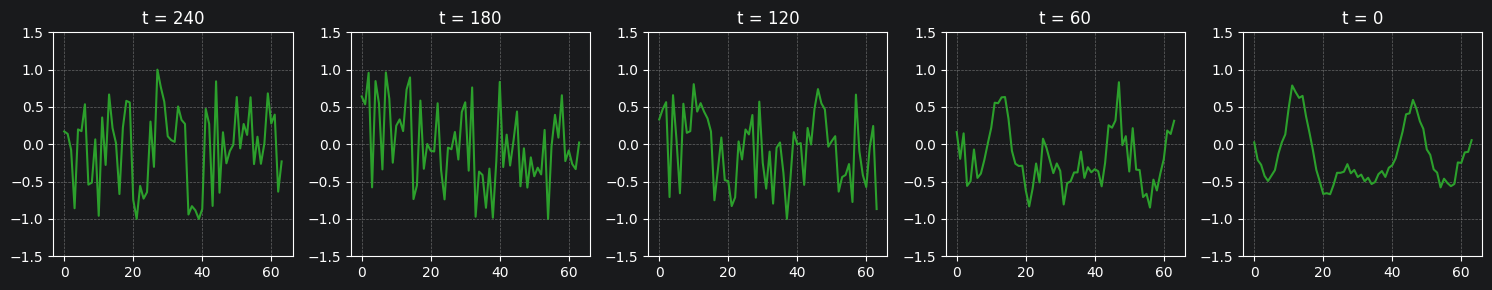

Epoch 010/100 | Loss media: 0.09028


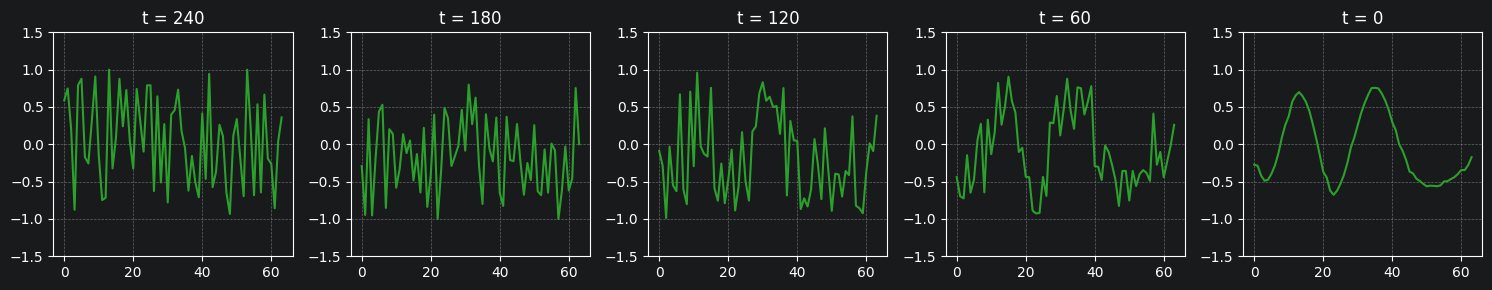

Epoch 020/100 | Loss media: 0.08646


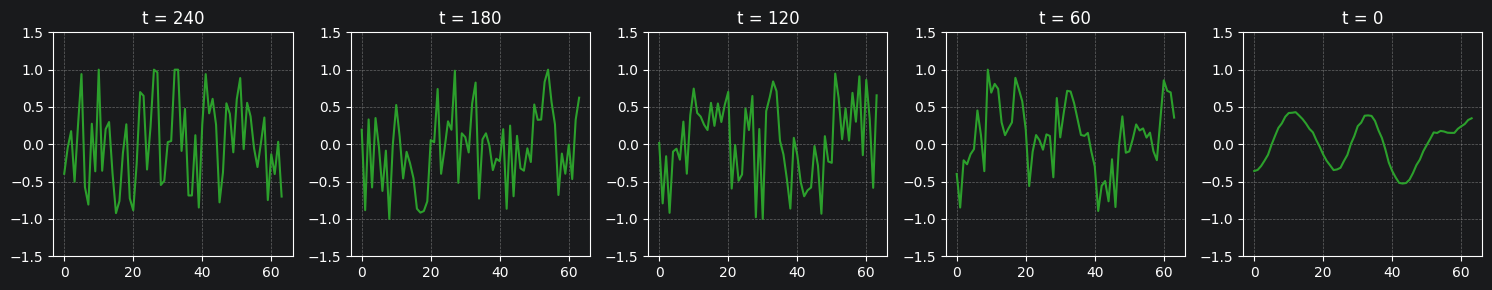

Epoch 030/100 | Loss media: 0.07792


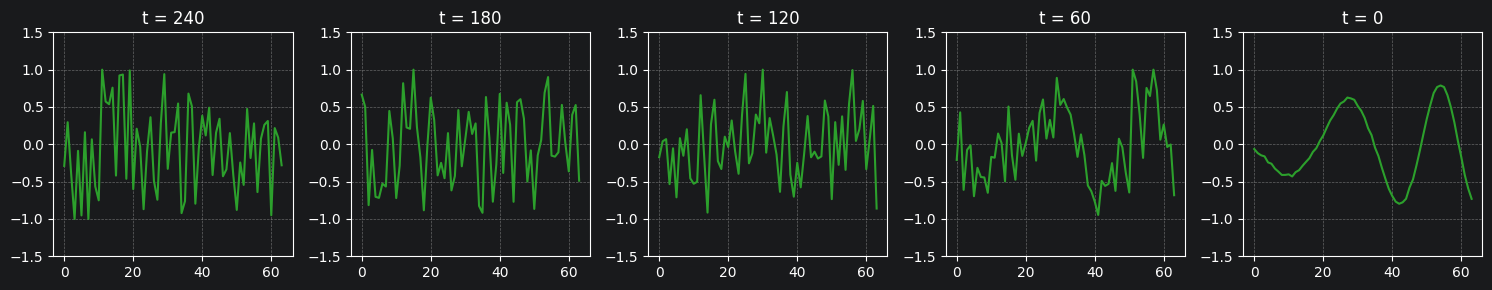

Epoch 040/100 | Loss media: 0.06982


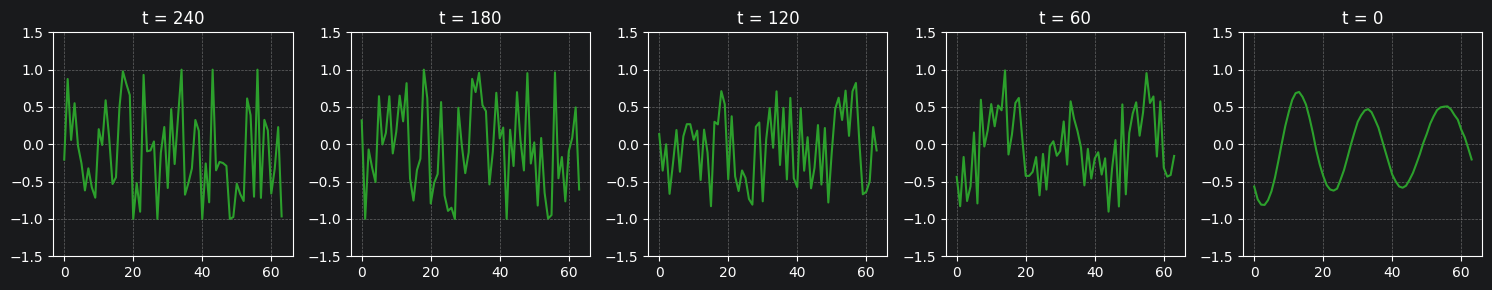

Epoch 050/100 | Loss media: 0.07525


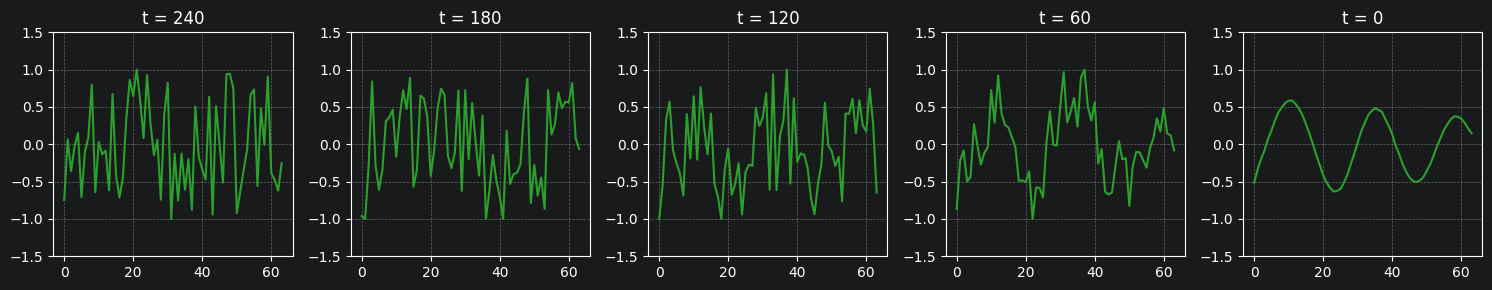

Epoch 060/100 | Loss media: 0.07557


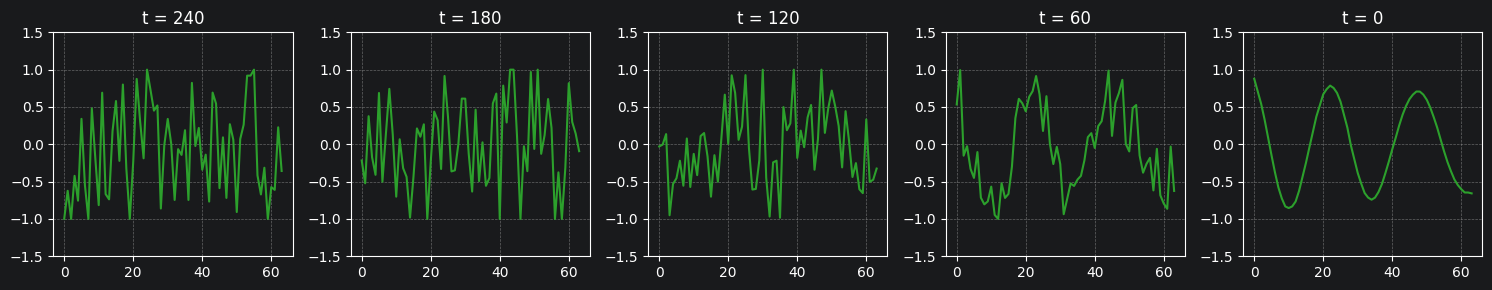

Epoch 070/100 | Loss media: 0.07417


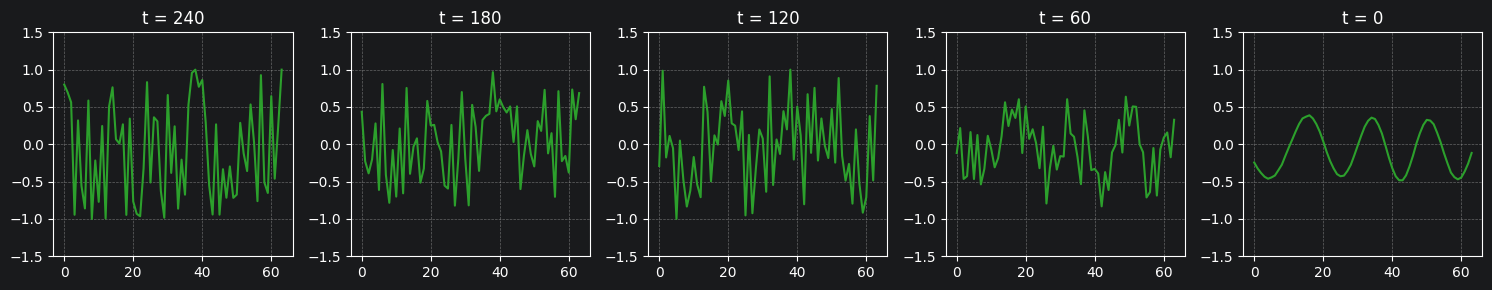

Epoch 080/100 | Loss media: 0.07456


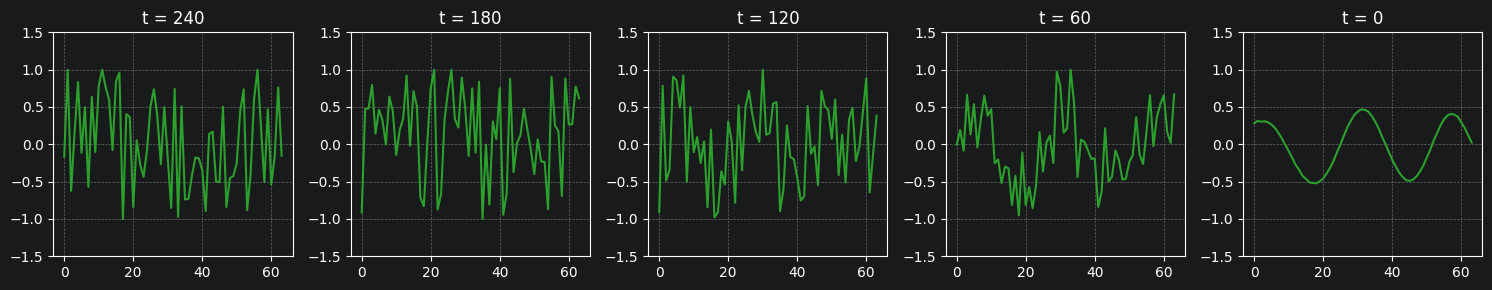

Epoch 090/100 | Loss media: 0.07541


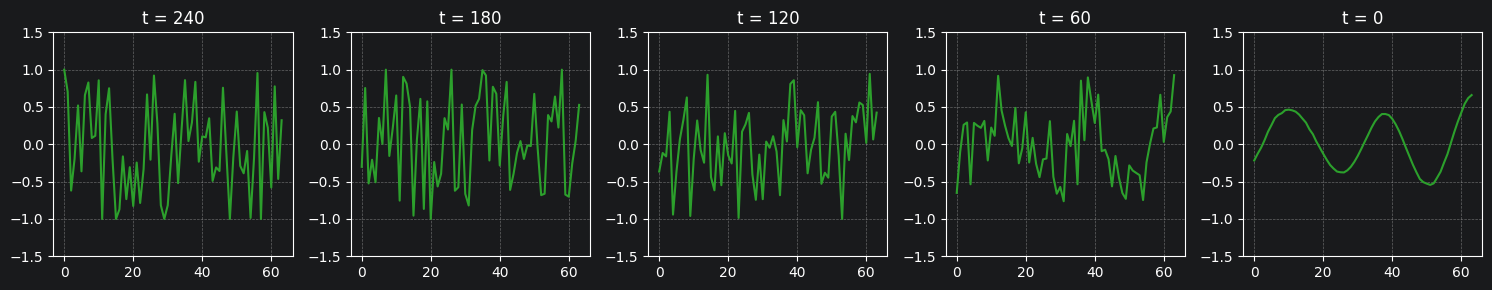

Epoch 099/100 | Loss media: 0.07362


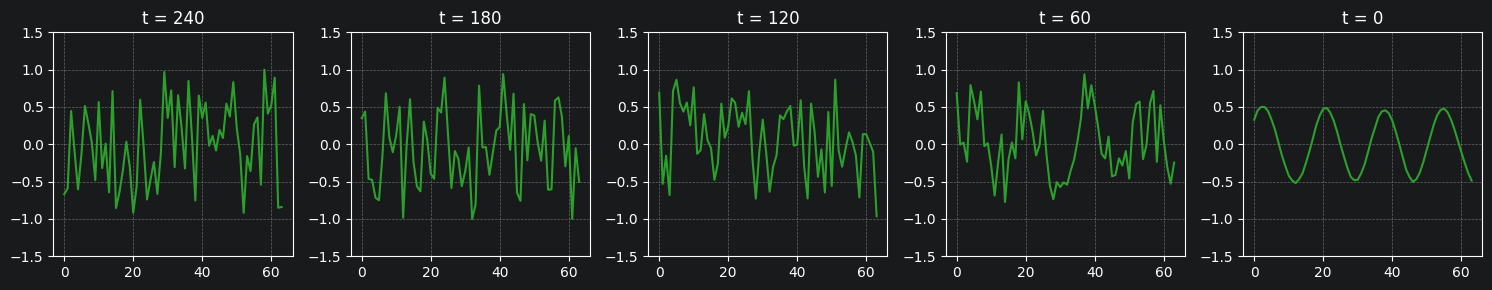

In [18]:
from torch.optim import Adam

# Configurazione
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Inizio addestramento su device: {device}")

model = SimpleUnet1D(in_channels=1, out_channels=1, time_emb_dim=32).to(device)
optimizer = Adam(model.parameters(), lr=0.001)

epochs = 100  # 100 epoche vanno benissimo per vedere l'evoluzione

# Ciclo di addestramento con plot intermedi
for epoch in range(epochs):
    model.train()  # FONDAMENTALE per il BatchNorm1d
    epoch_loss = 0.0

    for step, batch in enumerate(train_dataloader):
        optimizer.zero_grad()

        x_0 = batch[0].to(device)
        # Genera timestep casuali per questo batch
        t = torch.randint(0, T, (x_0.shape[0],), device=device).long()

        loss = get_loss(model, x_0, t)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_dataloader)

    # Ogni 10 epoche stampiamo la loss e mostriamo a che punto è la generazione
    if epoch % 10 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:03d}/{epochs} | Loss media: {avg_loss:.5f}")

        model.eval()  # FONDAMENTALE per la fase di generazione
        # Richiamiamo la funzione corretta per i segnali 1D
        sample_plot_wave(model, seq_len=seq_len, device=device)